           AI POLICY IMPACT SIMULATOR
Enter your Groq API key (press Enter for demo mode): ··········

Groq AI enabled.

POLICY SUBMISSION
Enter any policy in plain English.
After each report, you will be asked for another policy.
Type 'done' to finish and compare all entered policies.

Enter your policy (or type 'done'): AI-assisted disease detection in government hospitals.

Analyzing your policy. Please wait...

POLICY IMPACT REPORT #1

POLICY:
AI-assisted disease detection in government hospitals.

SUMMARY:
The policy proposes deploying artificial intelligence tools to assist clinicians in diagnosing diseases within government‑run hospitals, using patient data, imaging, and laboratory results to generate diagnostic suggestions and prioritize cases.

POTENTIAL BENEFITS
-------------------------------------------------------
 • Improved diagnostic accuracy and earlier detection of conditions, potentially reducing morbidity and mortality.
 • Increased efficiency of clinical workflows,

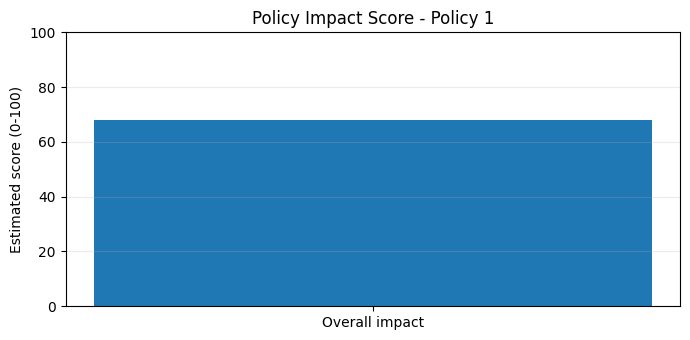


-----------------------------------------------------------------
Policy analysis completed successfully.
You can enter another policy now.
-----------------------------------------------------------------

Enter your policy (or type 'done'): Retraining programs for employees affected by AI automation.

Analyzing your policy. Please wait...

POLICY IMPACT REPORT #2

POLICY:
Retraining programs for employees affected by AI automation.

SUMMARY:
The policy proposes establishing or expanding training and reskilling programs aimed at workers whose jobs are displaced or transformed by artificial intelligence and automation technologies, with the goal of helping them transition to new roles or industries.

POTENTIAL BENEFITS
-------------------------------------------------------
 • Improves employability of displaced workers and reduces long‑term unemployment risk
 • Supports a more adaptable labor market, helping economies capture productivity gains from AI

POTENTIAL RISKS
--------------

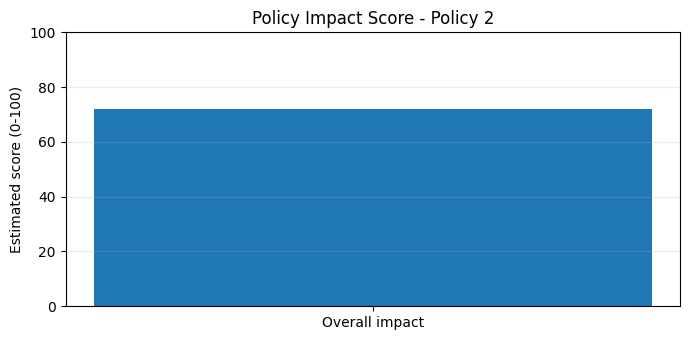


-----------------------------------------------------------------
Policy analysis completed successfully.
You can enter another policy now.
-----------------------------------------------------------------

Enter your policy (or type 'done'): done

You chose to finish the session.

FINAL POLICY COMPARISON

1. AI-assisted disease detection in government hospitals.
   Estimated impact score: 68/100

2. Retraining programs for employees affected by AI automation.
   Estimated impact score: 72/100


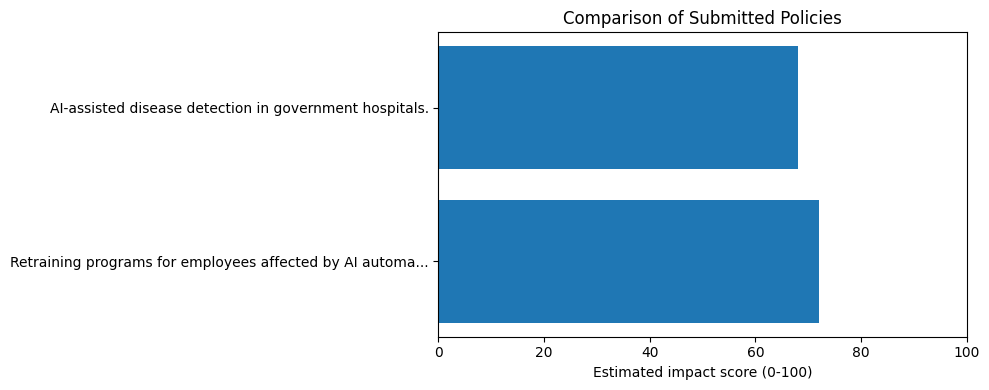


Session completed successfully.
You can rerun this cell to start a new session.


In [ ]:

# ================================================================
# AI POLICY IMPACT SIMULATOR
# Single Google Colab Cell | Dynamic Inputs | Reports + Charts
# ================================================================

!pip -q install -U groq matplotlib

import json
import getpass
import matplotlib.pyplot as plt
from groq import Groq

# ---------------------- CONFIGURATION ----------------------------

MODEL = "openai/gpt-oss-120b"
client = None

print("=" * 65)
print("           AI POLICY IMPACT SIMULATOR")
print("=" * 65)

api_key = getpass.getpass(
    "Enter your Groq API key (press Enter for demo mode): "
).strip()

if api_key:
    client = Groq(
        api_key=api_key,
        timeout=30.0,
        max_retries=1
    )
    print("\nGroq AI enabled.")
else:
    print("\nDemo mode enabled. Demo reports are generic examples.")

stakeholders = [
    "Citizens and public welfare",
    "Government and public finances",
    "Businesses and employment",
    "Environment and sustainability",
    "Technology and innovation"
]

policies = []
scores = []

# ---------------------- POLICY ANALYSIS --------------------------

def analyze_policy(policy):
    if client is None:
        return {
            "summary": f"Policy submitted: {policy}",
            "benefits": [
                "May address the problem targeted by the policy.",
                "Could improve outcomes if implemented effectively."
            ],
            "risks": [
                "Implementation costs and unintended consequences.",
                "Different groups may experience different outcomes."
            ],
            "stakeholder_impacts": {
                stakeholder:
                "Assess costs, benefits, accessibility, and possible risks."
                for stakeholder in stakeholders
            },
            "challenges": [
                "Funding and implementation.",
                "Monitoring results and ensuring fairness."
            ],
            "recommendations": [
                "Start with a pilot program.",
                "Measure results and revise the policy using evidence."
            ],
            "score": 50,
            "score_reason": "Demo placeholder score, not an AI prediction."
        }

    prompt = f"""
Analyze this policy without assuming a predefined category.

POLICY: {policy}

Evaluate:
1. Summary
2. Potential benefits
3. Potential risks
4. Impact on citizens, government finances, businesses and employment,
   the environment, and technology and innovation
5. Implementation challenges
6. Practical recommendations
7. An estimated overall impact score from 0 to 100

Consider feasibility, fairness, public benefit, sustainability, and risks.
Explain uncertainty. Do not invent statistics or present predictions
as guaranteed facts.

Return ONLY valid JSON in this structure:
{{
  "summary": "string",
  "benefits": ["string", "string"],
  "risks": ["string", "string"],
  "stakeholder_impacts": {{
    "Citizens and public welfare": "string",
    "Government and public finances": "string",
    "Businesses and employment": "string",
    "Environment and sustainability": "string",
    "Technology and innovation": "string"
  }},
  "challenges": ["string", "string"],
  "recommendations": ["string", "string"],
  "score": 65,
  "score_reason": "string"
}}
"""

    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {
                "role": "system",
                "content": "You are a careful, balanced policy analysis assistant."
            },
            {"role": "user", "content": prompt}
        ],
        temperature=0.2,
        max_completion_tokens=1600
    )

    content = response.choices[0].message.content or ""
    content = content.replace("```json", "").replace("```", "").strip()

    start = content.find("{")
    end = content.rfind("}")

    if start == -1 or end == -1:
        raise ValueError("The AI returned an unreadable response.")

    return json.loads(content[start:end + 1])


# ---------------------- DISPLAY REPORT ---------------------------

def show_list(title, items):
    print(f"\n{title}")
    print("-" * 55)

    if isinstance(items, list):
        for item in items:
            print(" •", item)
    elif items:
        print(" •", items)
    else:
        print(" • No information provided.")


def display_report(policy, report, number):
    print("\n" + "=" * 65)
    print(f"POLICY IMPACT REPORT #{number}")
    print("=" * 65)

    print("\nPOLICY:")
    print(policy)

    print("\nSUMMARY:")
    print(report.get("summary", "Not available"))

    show_list("POTENTIAL BENEFITS", report.get("benefits", []))
    show_list("POTENTIAL RISKS", report.get("risks", []))

    print("\nSTAKEHOLDER IMPACTS")
    print("-" * 55)

    impacts = report.get("stakeholder_impacts", {})

    for stakeholder in stakeholders:
        print(f"\n{stakeholder}:")
        print(impacts.get(stakeholder, "Not available"))

    show_list(
        "IMPLEMENTATION CHALLENGES",
        report.get("challenges", [])
    )

    show_list(
        "RECOMMENDATIONS",
        report.get("recommendations", [])
    )

    try:
        score = float(report.get("score", 50))
        score = max(0, min(100, score))
    except (ValueError, TypeError):
        score = 50

    print(f"\nOVERALL IMPACT SCORE: {score:.0f}/100")
    print("Score explanation:")
    print(report.get("score_reason", "Not available"))

    print("\nNote: AI-generated analysis is an estimate, not a guarantee.")

    # Draw the chart
    plt.figure(figsize=(7, 3.5))
    plt.bar(["Overall impact"], [score])
    plt.ylim(0, 100)
    plt.ylabel("Estimated score (0-100)")
    plt.title(f"Policy Impact Score - Policy {number}")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()
    plt.close()

    return score


# ---------------------- INTERACTIVE INPUT LOOP -------------------

print("\n" + "=" * 65)
print("POLICY SUBMISSION")
print("=" * 65)
print("Enter any policy in plain English.")
print("After each report, you will be asked for another policy.")
print("Type 'done' to finish and compare all entered policies.")
print("=" * 65)

while True:
    try:
        policy = input(
            "\nEnter your policy (or type 'done'): "
        ).strip()
    except (EOFError, KeyboardInterrupt):
        print("\nInput interrupted. Preparing final comparison.")
        break

    if policy.lower() in ("done", "exit", "quit"):
        print("\nYou chose to finish the session.")
        break

    if not policy:
        print("Please enter a policy before continuing.")
        continue

    print("\nAnalyzing your policy. Please wait...")

    try:
        report = analyze_policy(policy)
        score = display_report(policy, report, len(policies) + 1)

        policies.append(policy)
        scores.append(score)

        print("\n" + "-" * 65)
        print("Policy analysis completed successfully.")
        print("You can enter another policy now.")
        print("-" * 65)

    except Exception as error:
        print("\nCould not complete this policy analysis.")
        print("Error:", str(error))
        print("You can try the same policy again or enter a different one.")
        continue

# ---------------------- FINAL COMPARISON -------------------------

print("\n" + "=" * 65)
print("FINAL POLICY COMPARISON")
print("=" * 65)

if policies:
    for index, (policy, score) in enumerate(
        zip(policies, scores), start=1
    ):
        print(f"\n{index}. {policy}")
        print(f"   Estimated impact score: {score:.0f}/100")

    plt.figure(figsize=(10, max(4, len(policies) * 0.7)))

    labels = [
        policy[:55] + ("..." if len(policy) > 55 else "")
        for policy in policies
    ]

    plt.barh(labels, scores)
    plt.xlabel("Estimated impact score (0-100)")
    plt.xlim(0, 100)
    plt.title("Comparison of Submitted Policies")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
    plt.close()

    print("\nSession completed successfully.")
else:
    print("No policies were analyzed in this session.")

print("You can rerun this cell to start a new session.")
